# Delivery KPI Analysis

End-to-end: load raw Olist CSVs → explore → build `fct_orders` → data-quality checks → KPIs → export CSVs for Tableau (`outputs/`).

**Kernel:** Python (delivery .venv). Run top to bottom. The last cell closes the DuckDB connection — run it before using `run_sql.py` or the agent from a terminal (DuckDB allows one writer at a time).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from run_sql import connect, run_file

OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

con = connect()

## 1. Load raw data

In [2]:
run_file(con, ROOT / 'sql/00_load_raw.sql')


=== 00_load_raw.sql ===



-- Row counts
┌─────────────────┬────────┐
│       tbl       │   n    │
│     varchar     │ int64  │
├─────────────────┼────────┤
│ raw_orders      │  99441 │
│ raw_order_items │ 112650 │
│ raw_customers   │  99441 │
│ raw_sellers     │   3095 │
└─────────────────┴────────┘



## 2. Explore raw data
Notes from exploration feed the design decisions in `sql/01_build_fct_orders.sql`.

### 2.1 Tables: columns and sample rows

In [3]:
for t in ["raw_orders", "raw_order_items", "raw_customers", "raw_sellers"]:
    print(t)
    display(con.sql(f"DESCRIBE {t}").df())
    display(con.sql(f"SELECT * FROM {t} LIMIT 3").df())


raw_orders


,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,order_status,VARCHAR,YES,None,None,None
3,order_purchase_timestamp,TIMESTAMP,YES,None,None,None
4,order_approved_at,TIMESTAMP,YES,None,None,None
5,order_delivered_carrier_date,TIMESTAMP,YES,None,None,None
6,order_delivered_customer_date,TIMESTAMP,YES,None,None,None
7,order_estimated_delivery_date,TIMESTAMP,YES,None,None,None


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


raw_order_items


,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,order_item_id,BIGINT,YES,None,None,None
2,product_id,VARCHAR,YES,None,None,None
3,seller_id,VARCHAR,YES,None,None,None
4,shipping_limit_date,TIMESTAMP,YES,None,None,None
5,price,DOUBLE,YES,None,None,None
6,freight_value,DOUBLE,YES,None,None,None


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


... (2 outputs left out)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


raw_sellers


,column_name,column_type,null,key,default,extra
0,seller_id,VARCHAR,YES,None,None,None
1,seller_zip_code_prefix,VARCHAR,YES,None,None,None
2,seller_city,VARCHAR,YES,None,None,None
3,seller_state,VARCHAR,YES,None,None,None


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


### 2.2 Order status distribution

In [4]:
con.sql("""
    SELECT order_status, COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM raw_orders GROUP BY 1 ORDER BY n DESC
""").df()


,order_status,n,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


### 2.3 Missing timestamps by status

In [5]:
con.sql("""
    SELECT order_status,
           COUNT(*) AS n,
           COUNT(*) - COUNT(order_approved_at)             AS null_approved,
           COUNT(*) - COUNT(order_delivered_carrier_date)  AS null_carrier,
           COUNT(*) - COUNT(order_delivered_customer_date) AS null_delivered
    FROM raw_orders GROUP BY 1 ORDER BY n DESC
""").df()


,order_status,n,null_approved,null_carrier,null_delivered
0,delivered,96478,14,2,8
1,shipped,1107,0,0,1107
2,canceled,625,141,550,619
3,unavailable,609,0,609,609
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,created,5,5,5,5
7,approved,2,0,2,2


### 2.4 Date range

In [6]:
con.sql("""
    SELECT MIN(order_purchase_timestamp), MAX(order_purchase_timestamp)
    FROM raw_orders
""").df()


,min(order_purchase_timestamp),max(order_purchase_timestamp)
0,2016-09-04 21:15:19,2018-10-17 17:30:18


### 2.5 Orders per month

<Axes: xlabel='month'>

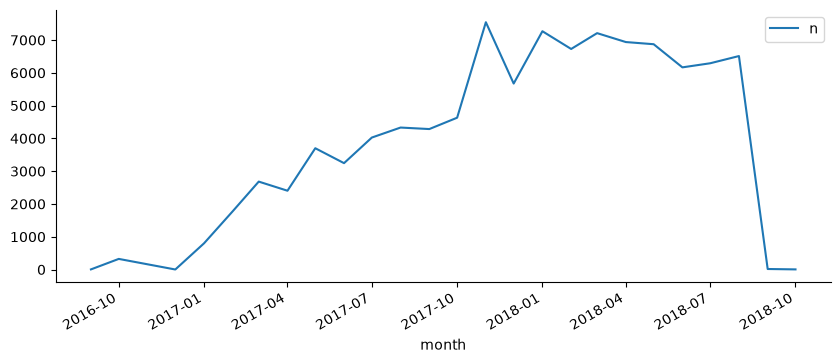

In [7]:
df = con.sql("""
    SELECT date_trunc('month', order_purchase_timestamp) AS month, COUNT(*) AS n
    FROM raw_orders GROUP BY 1 ORDER BY 1
""").df()
df.plot(x="month", y="n", figsize=(10, 4))


### 2.6 Rough lead time / delay distribution

,lead_days,delay_days
count,96470.0,96470.0
mean,12.496849,-11.875889
std,9.555071,10.182105
min,0.0,-147.0
25%,7.0,-17.0
50%,10.0,-12.0
75%,16.0,-7.0
max,210.0,188.0


array([[<Axes: title={'center': 'lead_days'}>,
        <Axes: title={'center': 'delay_days'}>]], dtype=object)

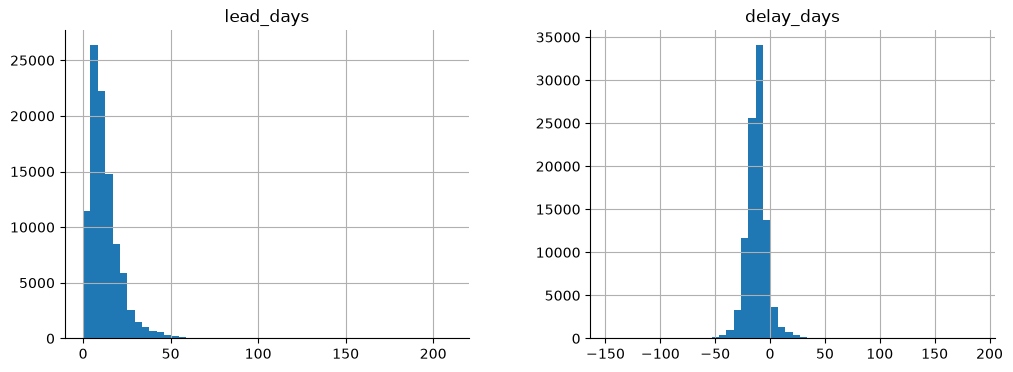

In [8]:
import matplotlib.pyplot as plt

df = con.sql("""
    SELECT date_diff('day', order_purchase_timestamp, order_delivered_customer_date) AS lead_days,
           date_diff('day', order_estimated_delivery_date, order_delivered_customer_date) AS delay_days
    FROM raw_orders WHERE order_status = 'delivered'
""").df()
display(df.describe())
df.hist(bins=50, figsize=(12, 4))


### 2.7 Sellers per order

In [9]:
con.sql("""
    WITH s AS (
        SELECT order_id, COUNT(DISTINCT seller_id) AS n_sellers
        FROM raw_order_items GROUP BY 1
    )
    SELECT n_sellers, COUNT(*) AS n_orders FROM s GROUP BY 1 ORDER BY 1
""").df()


,n_sellers,n_orders
0,1,97388
1,2,1219
2,3,54
3,4,3
4,5,2


### 2.8 Orders by customer state

In [10]:
con.sql("""
    SELECT c.customer_state, COUNT(*) AS n
    FROM raw_orders o JOIN raw_customers c USING (customer_id)
    GROUP BY 1 ORDER BY n DESC
""").df()


,customer_state,n
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


**Findings**
- 96,478 of 99,441 orders (97%) are `delivered`; 8 of them have no delivery date, 2 have no carrier date.
- Data runs 2016-09 to 2018-10, but only 2017-01 to 2018-08 has meaningful volume → monthly trends use that window.
- 98% of orders have a single seller → `seller_state` = seller of the first item, `n_sellers` kept as a column.
- Some timestamps are out of order (shipped before purchase, delivered before shipped) and a few lead times exceed 100 days → tagged and excluded.

## 3. Build `fct_orders`

In [11]:
run_file(con, ROOT / 'sql/01_build_fct_orders.sql')
con.sql('SELECT * FROM fct_orders LIMIT 5').df()


=== 01_build_fct_orders.sql ===



-- fct_orders row count
┌────────┐
│ n_rows │
│ int64  │
├────────┤
│  96217 │
└────────┘



,order_id,customer_id,purchase_month,purchase_ts,carrier_ts,delivered_ts,estimated_date,customer_state,seller_state,n_sellers,is_cross_state,handling_days,transit_days,total_lead_days,delay_days,is_late
0,00e7ee1b050b8499577073aeb2a297a1,06b8999e2fba1a1fbc88172c00ba8bc7,2017-05-01,2017-05-16 15:05:35,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,SP,SP,1,False,6.82,1.99,8.81,-11,False
1,29150127e6685892b6eab3eec79f59c7,18955e83d337fd6b2def6b18a428ac77,2018-01-01,2018-01-12 20:48:24,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,SP,SC,1,True,2.85,13.81,16.66,-8,False
2,b2059ed67ce144a36e2aa97d2c9e9ad2,4e7b3e00288586ebd08712fdd0374a03,2018-05-01,2018-05-19 16:07:45,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,SP,SP,1,False,22.93,3.14,26.08,1,True
3,951670f92359f4fe4a63112aa7306eba,b2b6027bc5c5109e529d4dc6358b12c3,2018-03-01,2018-03-13 16:06:38,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,SP,SP,1,False,14.30,0.70,15.00,-13,False
4,6b7d50bd145f6fc7f33cebabd7e49d0f,4f2d8ab171c80ec8364f7c12e35b23ad,2018-07-01,2018-07-29 09:51:30,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,SP,SP,1,False,1.23,10.24,11.46,-6,False


In [12]:
con.sql('SELECT handling_days, transit_days, total_lead_days, delay_days FROM fct_orders').df().describe().round(2)

,handling_days,transit_days,total_lead_days,delay_days
count,96217.00,96217.00,96217.00,96217.00
mean,3.23,9.25,12.48,-11.95
std,3.50,8.05,8.89,9.61
min,0.00,0.00,0.53,-147.00
25%,1.13,4.10,6.77,-17.00
50%,2.20,7.10,10.22,-12.00
75%,4.07,12.03,15.72,-7.00
max,66.05,98.96,99.95,83.00


## 4. Data-quality checks

In [13]:
run_file(con, ROOT / 'sql/02_data_quality_checks.sql')


=== 02_data_quality_checks.sql ===

-- DQ summary
┌─────────────────────────────────────────────────┬────────┬──────────────────────────────────┐
│                   check_name                    │ n_rows │             handling             │
│                     varchar                     │ int64  │             varchar              │
├─────────────────────────────────────────────────┼────────┼──────────────────────────────────┤
│ DQ1 duplicate order_id in fct_orders            │      0 │ should be 0 (join fan-out check) │
│ DQ2 timestamps out of order                     │    188 │ excluded from fct_orders         │
│ DQ3 delivered but missing delivery/carrier date │      9 │ excluded from fct_orders         │
│ DQ4 lead time < 0 or > 100 days                 │     64 │ excluded from fct_orders         │
└─────────────────────────────────────────────────┴────────┴──────────────────────────────────┘


-- Exclusions by dq_issue
┌──────────────────────────┬────────┐
│         dq_issue 

## 5. KPI analysis
The SQL lives in `sql/03_kpi_analysis.sql` and creates one `kpi*` view per question.

In [14]:
run_file(con, ROOT / 'sql/03_kpi_analysis.sql', verbose=False)
con.sql('SELECT * FROM kpi_headline').df()


=== 03_kpi_analysis.sql ===


,delivered_orders,on_time_rate_pct,avg_lead_days
0,96217,93.28,12.48


### KPI1 Monthly on-time rate

,purchase_month,n_orders,on_time_rate_pct
14,2018-03-01,7002,81.05
13,2018-02-01,6551,85.93
10,2017-11-01,7279,87.70


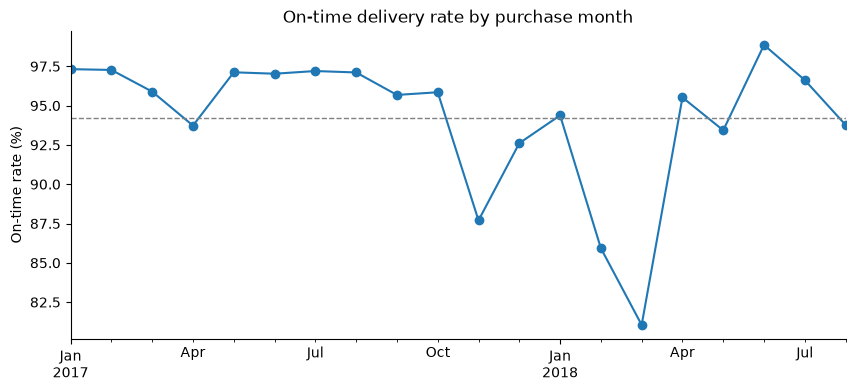

In [15]:
k1 = con.sql('SELECT * FROM kpi1_monthly_ontime').df()
ax = k1.plot(x='purchase_month', y='on_time_rate_pct', marker='o', legend=False, title='On-time delivery rate by purchase month')
ax.axhline(k1.on_time_rate_pct.mean(), ls='--', c='grey', lw=1)
ax.set_ylabel('On-time rate (%)'); ax.set_xlabel('')
k1.sort_values('on_time_rate_pct').head(3)

### KPI2 Lead time: handling vs transit

,stage,avg_days,median_days,share_of_total_pct
0,handling,3.23,2.20,25.9
1,transit,9.25,7.10,74.1
2,total,12.48,10.22,100.0


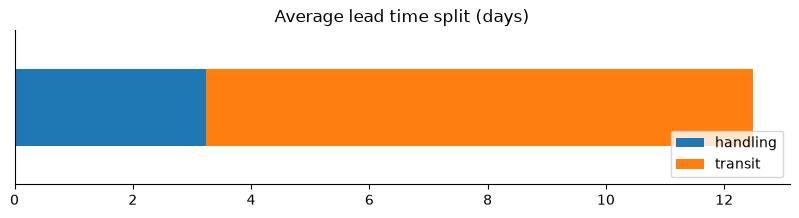

In [16]:
k2 = con.sql('SELECT * FROM kpi2_lead_time_breakdown').df()
ax = k2[k2.stage != 'total'].set_index('stage')[['avg_days']].T.plot.barh(stacked=True, title='Average lead time split (days)', figsize=(10, 2))
ax.set_yticks([]); ax.legend(loc='lower right')
k2

### KPI3 Worst states by on-time rate

,customer_state,n_orders,on_time_rate_pct,avg_handling_days,avg_transit_days
0,AL,397,78.59,3.46,21.09
1,MA,713,82.61,3.62,17.79
2,SE,332,85.24,3.60,16.92
3,PI,471,86.41,3.18,15.59
4,CE,1274,86.50,3.33,17.59


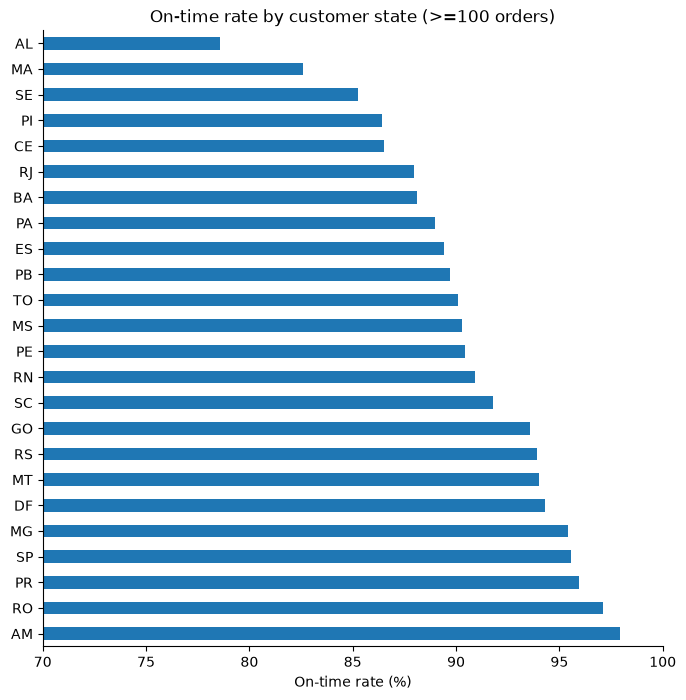

In [17]:
k3 = con.sql('SELECT * FROM kpi3_state_ontime').df()
ax = k3.sort_values('on_time_rate_pct', ascending=False).plot.barh(x='customer_state', y='on_time_rate_pct', legend=False, figsize=(8, 8), title='On-time rate by customer state (>=100 orders)')
ax.set_xlim(70, 100); ax.set_xlabel('On-time rate (%)'); ax.set_ylabel('')
k3.head(5)

### KPI4 Cross-state vs same-state

,route_type,n_orders,late_rate_pct,avg_transit_days,avg_total_lead_days
0,cross-state,61589,7.98,11.77,15.05
1,same-state,34628,4.48,4.77,7.91


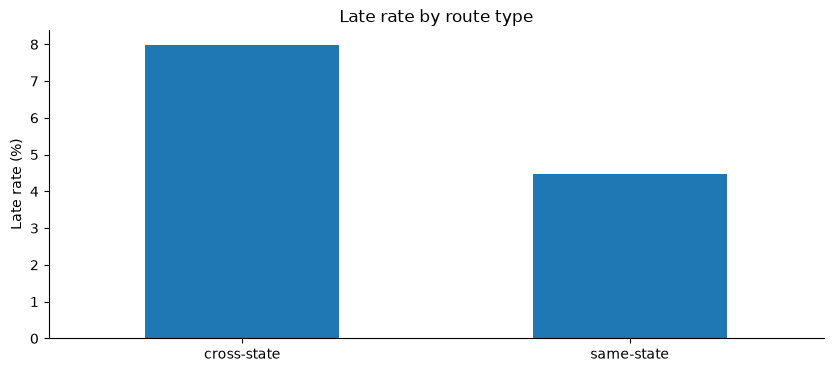

In [18]:
k4 = con.sql('SELECT * FROM kpi4_cross_state').df()
ax = k4.plot.bar(x='route_type', y='late_rate_pct', legend=False, rot=0, title='Late rate by route type')
ax.set_ylabel('Late rate (%)'); ax.set_xlabel('')
k4

### KPI5 Delay distribution

,delay_bucket,n_orders,pct
0,1. 15+ days early,34837,36.21
1,2. 8-14 days early,36308,37.74
2,3. 1-7 days early,17314,17.99
3,4. on estimated day,1291,1.34
4,5. 1-3 days late,1869,1.94
5,6. 4-7 days late,1800,1.87
6,7. 8+ days late,2798,2.91


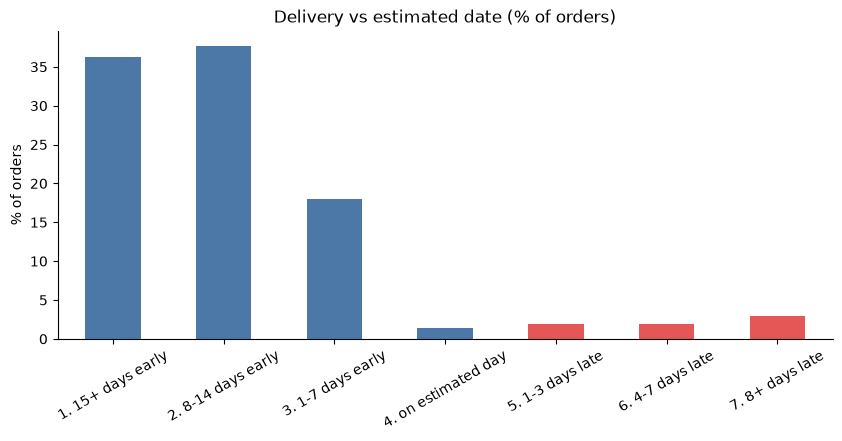

In [19]:
k5 = con.sql('SELECT * FROM kpi5_delay_distribution').df()
colors = ['#4c78a8'] * 4 + ['#e45756'] * 3
ax = k5.plot.bar(x='delay_bucket', y='pct', legend=False, color=colors, rot=30, title='Delivery vs estimated date (% of orders)')
ax.set_ylabel('% of orders'); ax.set_xlabel('')
k5

## 6. Export for Tableau

In [20]:
con.sql('SELECT * FROM fct_orders').df().to_csv(OUT / 'fct_orders.csv', index=False)
for v in ['kpi_headline', 'kpi1_monthly_ontime', 'kpi2_lead_time_breakdown', 'kpi3_state_ontime', 'kpi4_cross_state', 'kpi5_delay_distribution']:
    con.sql(f'SELECT * FROM {v}').df().to_csv(OUT / f'{v}.csv', index=False)
sorted(p.name for p in OUT.glob('*.csv'))

['fct_orders.csv',
 'kpi1_monthly_ontime.csv',
 'kpi2_lead_time_breakdown.csv',
 'kpi3_state_ontime.csv',
 'kpi4_cross_state.csv',
 'kpi5_delay_distribution.csv',
 'kpi_headline.csv']

In [21]:
con.close()